In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [2]:
TRAIN = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
TEST = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
SAMPLE = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")

In [3]:
from kaggle_secrets import UserSecretsClient
import wandb

user_secrets = UserSecretsClient()
wandb_api = user_secrets.get_secret("WANDB_API_KEY")

wandb.login(key=wandb_api)

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [4]:
import torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [5]:
TRAIN.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [6]:
len(TRAIN)

2000

In [7]:
TRAIN.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

In [8]:
TRAIN["answer"].value_counts()

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

In [9]:
TRAIN.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


In [10]:
TRAIN.describe()

,id
count,2000.000000
mean,1000.500000
std,577.494589
min,1.000000
25%,500.750000
50%,1000.500000
75%,1500.250000
max,2000.000000


answer
B    24.50
C    22.95
A    18.45
D    17.90
E    16.20
Name: count, dtype: float64


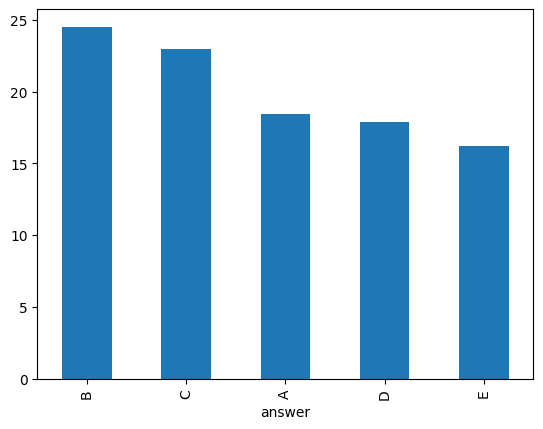

In [11]:
((TRAIN.answer.value_counts()/2000) * 100).plot.bar()
print((TRAIN.answer.value_counts()/2000) * 100)

In [14]:
# max_length_train = TRAIN["prompt"].str.split().str.len().max()
# max_length_test = TEST["prompt"].str.split().str.len().max()
# max_length = max_length_train if max_length_test < max_length_train else max_length_test
# print("Max length for string:", max_length)

In [15]:
common = set(TRAIN["prompt"]) & set(TEST["prompt"])
print("Percentage of common questions between train and test data:", len(common)/len(TEST) * 100)

Percentage of common questions between train and test data: 53.400000000000006


In [16]:
from transformers import AutoTokenizer, AutoModelForMultipleChoice

model_name = "FacebookAI/roberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForMultipleChoice.from_pretrained(model_name)

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForMultipleChoice LOAD REPORT from: FacebookAI/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.bias                 | MISSING    | 
roberta.pooler.dense.weight     | MISSING    | 
classifier.weight               | MISSING    | 
roberta.pooler.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [17]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(TRAIN, test_size=0.2, random_state=42, stratify=TRAIN["answer"])

In [18]:
from torch.utils.data import Dataset, DataLoader

class MCQDataset(Dataset):
    def __init__(self, data, tokenizer, max_length):
        self.data = data
        self.tokenizer = tokenizer
        self.max_len = max_length
        self.label_map = {
            "A": 0,
            "B": 1,
            "C": 2,
            "D": 3,
            "E": 4
        }
        
    def __len__(self):
        return len(self.data)
        
    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        prompt = row["prompt"]
        choices=[row["A"], row["B"], row["C"], row["D"], row["E"]]
        label = self.label_map[row["answer"]]
        tokenized = tokenizer([prompt]*5, choices, truncation=True, padding="max_length", max_length=max_length, return_tensors="pt")
        return {"input_ids": tokenized["input_ids"],
               "attention_mask": tokenized["attention_mask"],
               "labels": torch.tensor(label, dtype=torch.long)}

In [19]:
train_dataset = MCQDataset(data=train_df, tokenizer=tokenizer, max_length=256)
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)

In [45]:
val_dataset = MCQDataset(data=test_df, tokenizer=tokenizer, max_length=256)
val_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [21]:
steps_per_epoch = len(train_dataloader)/32
print(steps_per_epoch)
total_steps = 5 * steps_per_epoch
print(total_steps)

1.5625
7.8125


In [22]:
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

learning_rate = 2e-5
epochs = 5
optimizer = AdamW(model.parameters(), lr=learning_rate, weight_decay=0.01)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=25, num_training_steps=250)

In [25]:
wandb.init(
    project="Smart_MCQ_solver",
    name="roberta-base-run2",
    config={
        "epochs": epochs,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "batch_size": train_dataloader.batch_size,
        "model": "roberta-base"
    }
)

In [26]:
model = model.to(device)
model.train()

global_step = 0

for epoch in range(epochs):
    total_loss = 0

    for step, batch in enumerate(train_dataloader):
        batch = {k: v.to(device) for k, v in batch.items()}

        optimizer.zero_grad()

        outputs = model(**batch)
        loss = outputs.loss

        loss.backward()

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        wandb.log({
            "train/batch_loss": loss.item(),
            "learning_rate": scheduler.get_last_lr()[0],
            "global_step": global_step
        })
        global_step += 1
    avg_loss = total_loss / len(train_dataloader)

    print(f"Epoch {epoch+1}: Loss = {avg_loss:.4f}")
    wandb.log({"train/epoch_loss": avg_loss, "epoch": epoch + 1})

Epoch 1: Loss = 1.6022
Epoch 2: Loss = 1.3823
Epoch 3: Loss = 0.7297
Epoch 4: Loss = 0.4474
Epoch 5: Loss = 0.3893


In [44]:
print(val_dataset.data.columns)
print(type(val_dataset.data))

Index(['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer'], dtype='object')
<class 'pandas.core.frame.DataFrame'>


In [46]:
model.eval()

val_loss = 0
scores = []

with torch.no_grad():

    for batch in val_dataloader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        loss = outputs.loss
        logits = outputs.logits
        val_loss += loss.item()

        top3 = torch.topk(logits, k=3, dim=1).indices

        labels = batch["labels"]

        for true_label, pred in zip(labels, top3):

            pred = pred.tolist()
            true_label = true_label.item()

            if true_label in pred:
                ap = 1.0 / (pred.index(true_label) + 1)
            else:
                ap = 0.0

            scores.append(ap)

avg_val_loss = val_loss / len(val_dataloader)
val_map3 = sum(scores) / len(scores)

print(f"Validation Loss : {avg_val_loss:.4f}")
print(f"Validation MAP@3 : {val_map3:.4f}")

wandb.log({
    "val/loss": avg_val_loss,
    "val/MAP@3": val_map3
})
wandb.finish()

Validation Loss : 0.2870
Validation MAP@3 : 0.9354


epoch,▁▃▅▆█
global_step,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇███
learning_rate,▃▄▅██▇▇▇▇▇▆▆▆▅▅▅▅▅▅▅▄▄▄▄▄▃▃▃▃▃▂▂▂▂▂▂▂▂▂▁
train/batch_loss,██████████▇▇▆▇█▆▆▆▆▆▆▅▅▄▃▄▃▂▂▃▃▂▂▂▃▃▂▁▂▂
train/epoch_loss,█▇▃▁▁
val/MAP@3,▁
val/loss,▁
epoch,5
global_step,249
learning_rate,0
train/batch_loss,0.53031


In [47]:
class TestDataset(Dataset):
    def __init__(self, data, tokenizer, max_length):
        self.data = data
        self.tokenizer = tokenizer
        self.max_len = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        prompt = row["prompt"]
        choices = [row["A"], row["B"], row["C"], row["D"], row["E"]]

        tokenized = self.tokenizer(
            [prompt] * 5,
            choices,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids": tokenized["input_ids"],
            "attention_mask": tokenized["attention_mask"]
        }

In [48]:
test_dataset = TestDataset(TEST, tokenizer, max_length=256)

test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [63]:
# model=model.to(device)
# model.train()
# for epoch in range(epochs):
#     total_loss = 0 
#     for step, batch in enumerate(train_dataloader):
#         batch = {k: v.to(device) for k,v in batch.items()}
#         optimizer.zero_grad()

#         # for k, v in batch.items():
#         #     print(k, v.device, v.shape)
#         outputs = model(**batch)
#         loss = outputs.loss
#         loss.backward()
    
#         optimizer.step()
#         scheduler.step()
#         total_loss += loss.item()
#     avg_loss = total_loss/len(train_dataloader)
#     print('epoch :', epoch+1, 'loss: ', avg_loss)

epoch : 0 loss:  1.5967835903167724
epoch : 1 loss:  1.263754540681839
epoch : 2 loss:  0.7068609189987183
epoch : 3 loss:  0.5107795149087906
epoch : 4 loss:  0.4376256102323532


In [49]:
model.eval()
label_map = ["A", "B", "C", "D", "E"]
predictions = []
with torch.no_grad():
    for batch in test_dataloader:
        input_ids = batch["input_ids"].squeeze(1).to(device)
        attention_mask = batch["attention_mask"].squeeze(1).to(device)
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        logits = outputs.logits
        top3 = torch.topk(logits, k=3, dim=1).indices.cpu().numpy()
        for pred in top3:
            predictions.append(" ".join(label_map[i] for i in pred))

In [50]:
submission = pd.DataFrame({
    "id": TEST["id"],
    "prediction": predictions
})

submission.to_csv("submission.csv", index=False)

submission.head()

,id,prediction
0,1,A D C
1,2,B A D
2,3,B E D
3,4,E A C
4,5,B C A


In [51]:
len(submission)

500